# Real Estate Price Prediction using Multiple Linear Regression

## Problem

The goal of this project is to predict the house price per unit area using property and location features.

## Target

- Y house price of unit area

## Available Features

- X1 transaction date
- X2 house age
- X3 distance to the nearest MRT station
- X4 number of convenience stores
- X5 latitude
- X6 longitude

## Note

The `No` column is only a row identifier and will not be used as a predictive feature.

In [3]:
import pandas as pd

df = pd.read_csv("data/real_estate_valuation.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


In [5]:
df.shape

(414, 8)

In [6]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [8]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [9]:
df.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [10]:
df.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


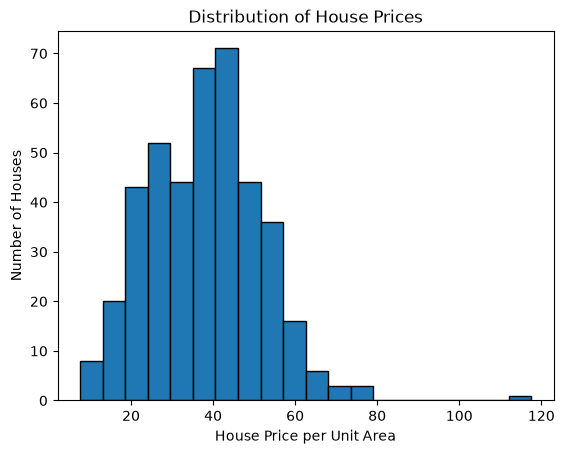

In [11]:
import matplotlib.pyplot as plt

plt.hist(
    df["Y house price of unit area"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("House Price per Unit Area")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")
plt.show()

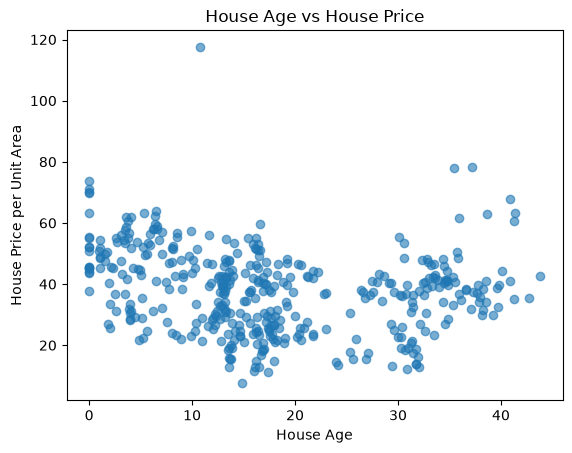

In [12]:
plt.scatter(
    df["X2 house age"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("House Age")
plt.ylabel("House Price per Unit Area")
plt.title("House Age vs House Price")
plt.show()

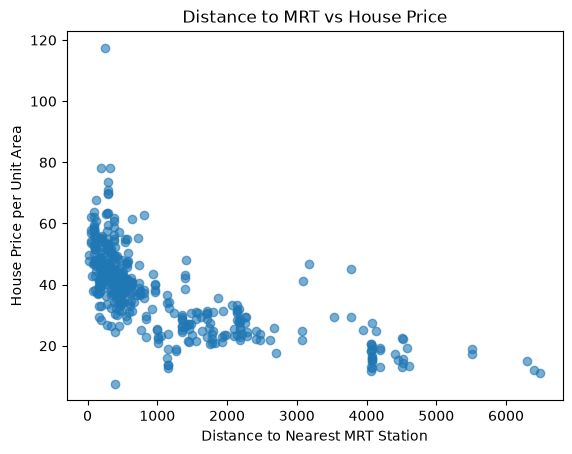

In [13]:
plt.scatter(
    df["X3 distance to the nearest MRT station"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("Distance to Nearest MRT Station")
plt.ylabel("House Price per Unit Area")
plt.title("Distance to MRT vs House Price")
plt.show()

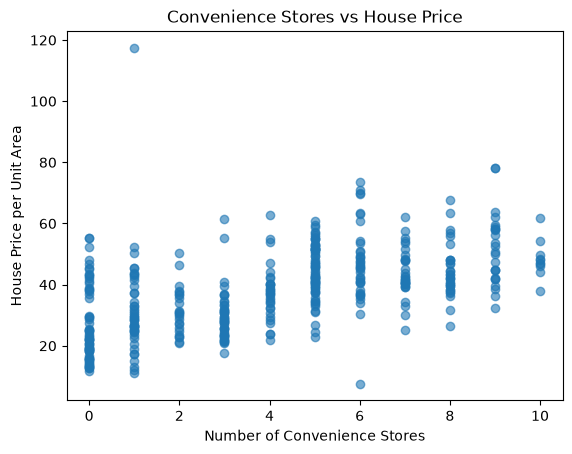

In [14]:
plt.scatter(
    df["X4 number of convenience stores"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("Number of Convenience Stores")
plt.ylabel("House Price per Unit Area")
plt.title("Convenience Stores vs House Price")
plt.show()

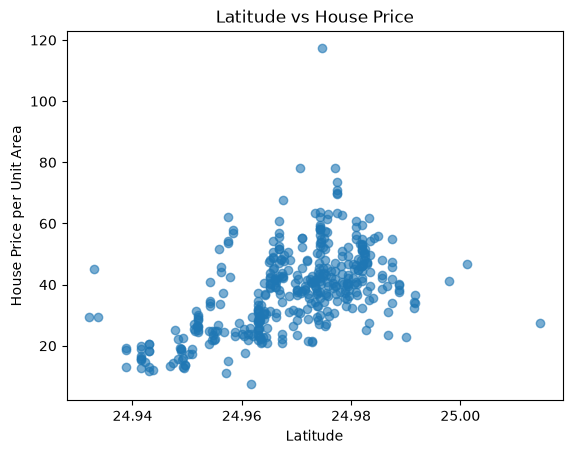

In [15]:
plt.scatter(
    df["X5 latitude"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("Latitude")
plt.ylabel("House Price per Unit Area")
plt.title("Latitude vs House Price")
plt.show()


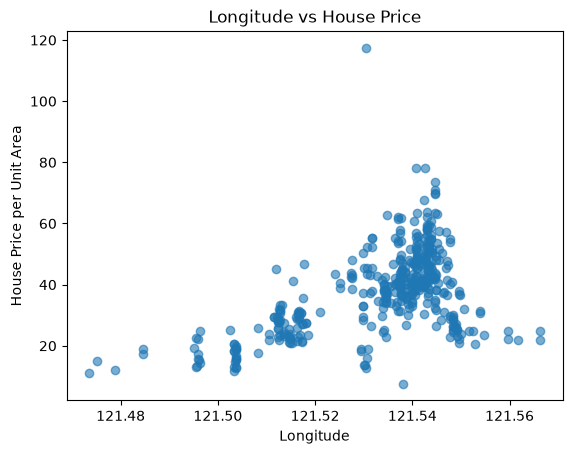

In [16]:
plt.scatter(
    df["X6 longitude"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("House Price per Unit Area")
plt.title("Longitude vs House Price")
plt.show()

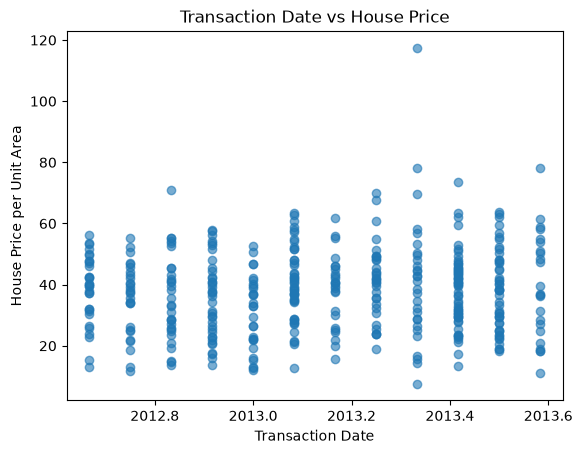

In [17]:

plt.scatter(
    df["X1 transaction date"],
    df["Y house price of unit area"],
    alpha=0.6
)

plt.xlabel("Transaction Date")
plt.ylabel("House Price per Unit Area")
plt.title("Transaction Date vs House Price")
plt.show()



In [18]:
correlations_with_price = (
    df.drop(columns=["No"])
      .corr()["Y house price of unit area"]
      .sort_values(ascending=False)
)

correlations_with_price

Y house price of unit area                1.000000
X4 number of convenience stores           0.571005
X5 latitude                               0.546307
X6 longitude                              0.523287
X1 transaction date                       0.087529
X2 house age                             -0.210567
X3 distance to the nearest MRT station   -0.673613
Name: Y house price of unit area, dtype: float64

In [19]:
feature_correlations = df.drop(
    columns=["No", "Y house price of unit area"]
).corr()

feature_correlations.round(2)

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
X1 transaction date,1.00,0.02,0.06,0.01,0.04,-0.04
X2 house age,0.02,1.00,0.03,0.05,0.05,-0.05
X3 distance to the nearest MRT station,0.06,0.03,1.00,-0.60,-0.59,-0.81
X4 number of convenience stores,0.01,0.05,-0.60,1.00,0.44,0.45
X5 latitude,0.04,0.05,-0.59,0.44,1.00,0.41
X6 longitude,-0.04,-0.05,-0.81,0.45,0.41,1.00


In [20]:
X = df.drop(columns=["No", "Y house price of unit area"])

y = df["Y house price of unit area"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (414, 6)
y shape: (414,)


In [21]:
X = df.drop(columns=["No", "Y house price of unit area"])

y = df["Y house price of unit area"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (414, 6)
y shape: (414,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (331, 6)
X_test: (83, 6)
y_train: (331,)
y_test: (83,)


In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [25]:
print("Intercept:", model.intercept_)

coefficients = pd.Series(
    model.coef_,
    index=X_train.columns
)

print(coefficients)

Intercept: -13048.14337937103
X1 transaction date                         5.443262
X2 house age                               -0.270794
X3 distance to the nearest MRT station     -0.004759
X4 number of convenience stores             1.091469
X5 latitude                               229.049043
X6 longitude                              -29.503389
dtype: float64


In [26]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head()

,Actual,Predicted
358,45.1,47.884596
350,42.3,41.163725
373,52.2,44.274719
399,37.3,40.195243
369,22.8,27.510367


In [27]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 5.3052329525851025


In [28]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 53.50225236117953


In [29]:
rmse = mse ** 0.5

print("RMSE:", rmse)

RMSE: 7.314523385783898


In [30]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R²:", r2)

R²: 0.6810781244679265


In [31]:
baseline_pred = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Model MAE:", mae)

Baseline MAE: 10.91674735194555
Model MAE: 5.3052329525851025
